# ☕ Does Coffee Add Years to Your Life? — Part 2: Analysis

This notebook analyses the clean cohort built in `01_cleaning_coffee.ipynb`:
**33,976 U.S. adults, 4,295 deaths, median follow-up 8.1 years** (NHANES 2003–2018,
deaths linked through 2019).

## Step 1 — Load, verify and describe the coffee groups (Table 1)

**Why this matters:** in the raw data, coffee drinkers die *more* often
(8.9% of non-drinkers vs 16.4% of heavy drinkers). But coffee drinkers are also
much older (median 41 vs 56) and heavy drinkers smoke twice as often. Table 1
shows these differences — which is why the main analysis must adjust for them.

Percentages and means are **survey-weighted**, so they represent the U.S. adult
population rather than just the people sampled.

**Gates:**
1. The file has exactly the people and deaths Notebook 1 reported (33,976 / 4,295)
2. One row per person, no missing values
3. All survey weights are positive
4. Group sizes in Table 1 add up to the full cohort

In [1]:
# Starting the analysis notebook. First, I install the survival-analysis library and import my tools.
!pip install lifelines -q
import os
import numpy as np
import pandas as pd
from google.colab import drive

# Now I reconnect Google Drive and load the clean cohort from Notebook 1.
drive.mount('/content/drive')
PROC = '/content/drive/MyDrive/coffee_lifespan/data/processed'
FIGS = '/content/drive/MyDrive/coffee_lifespan/figures'
os.makedirs(FIGS, exist_ok=True)

df = pd.read_parquet(os.path.join(PROC, 'analysis_cohort.parquet'))
labels = ['None', '≤1 cup', '1–2 cups', '2–3 cups', '>3 cups']
df['COFFEE_GROUP'] = pd.Categorical(df['COFFEE_GROUP'], categories=labels, ordered=True)

# GATE 1: the file must match exactly what Notebook 1 reported.
assert len(df) == 33976, f'GATE FAIL: expected 33,976 people, got {len(df):,}'
assert int(df['MORTSTAT'].sum()) == 4295, f'GATE FAIL: expected 4,295 deaths, got {int(df["MORTSTAT"].sum()):,}'

# GATE 2: one row per person and nothing missing (cause of death is only filled for those who died).
assert df['SEQN'].is_unique, 'GATE FAIL: duplicate people'
assert df.drop(columns='UCOD_LEADING').notna().all().all(), 'GATE FAIL: missing values found'

# GATE 3: every survey weight must be positive.
assert (df['WEIGHT'] > 0).all(), 'GATE FAIL: zero or negative survey weight'
print('File verified: matches Notebook 1 exactly.\n')

# Now I build Table 1 — how the coffee groups differ, weighted to represent U.S. adults.
def wmean(x, w):
    return np.average(x, weights=w)

def wpct(mask, w):
    return np.average(mask.astype(float), weights=w) * 100

rows = {}
for g, sub in df.groupby('COFFEE_GROUP', observed=True):
    w = sub['WEIGHT']
    rows[g] = {
        'People (unweighted)':      len(sub),
        'Deaths (unweighted)':      int(sub['MORTSTAT'].sum()),
        'Age, mean':                wmean(sub['RIDAGEYR'], w),
        'Male, %':                  wpct(sub['SEX'] == 'Male', w),
        'NH White, %':              wpct(sub['RACE'] == 'NH White', w),
        'College+, %':              wpct(sub['EDUCATION'] == 'College+', w),
        'Income-to-poverty, mean':  wmean(sub['INDFMPIR'], w),
        'Current smoker, %':        wpct(sub['SMOKING'] == 'Current', w),
        'Former smoker, %':         wpct(sub['SMOKING'] == 'Former', w),
        'BMI, mean':                wmean(sub['BMXBMI'], w),
        'Calories/day, mean':       wmean(sub['KCAL'], w),
        'Alcohol g/day, mean':      wmean(sub['ALCOHOL_G'], w),
        'Coffee cups/day, mean':    wmean(sub['COFFEE_CUPS'], w),
    }
table1 = pd.DataFrame(rows).round(1)

# GATE 4: the group sizes must add up to the whole cohort.
assert table1.loc['People (unweighted)'].sum() == len(df), 'GATE FAIL: Table 1 groups do not add up'
assert table1.loc['Deaths (unweighted)'].sum() == 4295, 'GATE FAIL: Table 1 deaths do not add up'

# Finally, I show the table and save it.
pd.set_option('display.width', 200)
print('Table 1 — Characteristics by coffee intake (survey-weighted)\n')
print(table1.to_string())
table1.to_csv(os.path.join(PROC, 'table1_characteristics.csv'))
print('\n✅ ALL GATES PASSED — data verified and Table 1 saved.')

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 409.1/409.1 kB 5.7 MB/s eta 0:00:00
Mounted at /content/drive
File verified: matches Notebook 1 exactly.

Table 1 — Characteristics by coffee intake (survey-weighted)

                            None  ≤1 cup  1–2 cups  2–3 cups  >3 cups
People (unweighted)      13814.0  5362.0    7313.0    3856.0   3631.0
Deaths (unweighted)       1230.0   697.0    1143.0     631.0    594.0
Age, mean                   42.1    47.7      51.5      52.8     52.8
Male, %                     48.6    39.9      44.3      50.1     57.6
NH White, %                 62.2    54.4      70.7      81.8     88.4
College+, %                 26.3    27.2      31.7      36.0     28.7
Income-to-poverty, mean      2.8     2.8       3.1       3.4      3.3
Current smoker, %           18.9    17.4      17.9      20.3     34.3
Former smoker, %            16.9    23.6      30.4      35.0     33.5
BMI, mean                   29.3    28.8      2

## Step 2 — Cox proportional hazards models

The Cox model compares the risk of death over time between coffee groups,
giving a **hazard ratio (HR)** with non-drinkers as the reference (HR = 1.00).
HR < 1 means lower risk; HR > 1 means higher risk.

**Three models:**
| Model | Adjusted for |
|-------|-------------|
| 1. Crude | nothing (coffee only) |
| 2. Age + sex | age, sex |
| 3. Fully adjusted | age, sex, race/ethnicity, education, income-to-poverty ratio, smoking, BMI, calories, alcohol |

- **Time:** months from the exam visit (when diet was recorded) to death or 31 Dec 2019
- **Survey weights** are used, with robust standard errors clustered on the NHANES
  design (strata × PSU). This is a close approximation to a full survey-design
  analysis.

**Gates:**
1. The model data has exactly 33,976 people and 4,295 deaths
2. Each coffee indicator column matches its group size exactly
3. All hazard ratios and confidence intervals are finite numbers
4. **Positive controls:** in the full model, age and current smoking must both
   increase death risk (HR > 1, statistically significant). If not, the model is wrong.

In [2]:
# Step 2 begins. Now I compare death risk across coffee groups with Cox survival models.
from lifelines import CoxPHFitter
import warnings
warnings.filterwarnings('ignore')   # lifelines warns about non-integer survey weights — expected

# First, I prepare the time and event columns.
d = df.copy()
d['T'] = d['PERMTH_EXM']          # months of follow-up from the exam
d['E'] = d['MORTSTAT']            # 1 = died, 0 = alive at end of 2019
print(f'People with 0 months of follow-up: {(d["T"] == 0).sum()} (kept — they count from day of exam)\n')

# Now I turn coffee groups into yes/no columns, with "None" as the reference.
for g in labels[1:]:
    d[f'COFFEE_{g}'] = (d['COFFEE_GROUP'] == g).astype(int)
coffee_cols = [f'COFFEE_{g}' for g in labels[1:]]

# GATE 2: each coffee column must match its group size exactly.
for g, col in zip(labels[1:], coffee_cols):
    assert d[col].sum() == (df['COFFEE_GROUP'] == g).sum(), f'GATE FAIL: {col} does not match group size'

# Next, I turn the other categories into yes/no columns, choosing a reference for each.
d['MALE'] = (d['SEX'] == 'Male').astype(int)
dummies = pd.get_dummies(d[['RACE', 'EDUCATION', 'SMOKING']].astype(str), dtype=int)
dummies = dummies.drop(columns=['RACE_NH White', 'EDUCATION_< High school', 'SMOKING_Never'])  # references
d = pd.concat([d, dummies], axis=1)

# I scale the survey weights to average 1 and build the cluster ID from the survey design.
d['W'] = d['WEIGHT'] / d['WEIGHT'].mean()
d['CLUSTER'] = d['CYCLE'] + '_' + d['SDMVSTRA'].astype(int).astype(str) + '_' + d['SDMVPSU'].astype(int).astype(str)

# GATE 1: the model data must contain the full cohort.
assert len(d) == 33976 and int(d['E'].sum()) == 4295, 'GATE FAIL: model data does not match the cohort'

# Now I define the three models.
models = {
    '1. Crude':          coffee_cols,
    '2. Age + sex':      coffee_cols + ['RIDAGEYR', 'MALE'],
    '3. Fully adjusted': coffee_cols + ['RIDAGEYR', 'MALE'] + list(dummies.columns)
                         + ['INDFMPIR', 'BMXBMI', 'KCAL', 'ALCOHOL_G'],
}

results, fitted = [], {}
for name, cols in models.items():
    # I fit each model with survey weights and clustered robust errors.
    cph = CoxPHFitter()
    cph.fit(d[cols + ['T', 'E', 'W', 'CLUSTER']], duration_col='T', event_col='E',
            weights_col='W', cluster_col='CLUSTER', robust=True)
    fitted[name] = cph
    s = cph.summary
    for g, col in zip(labels[1:], coffee_cols):
        results.append({'Model': name, 'Coffee': g,
                        'HR': s.loc[col, 'exp(coef)'],
                        'CI_low': s.loc[col, 'exp(coef) lower 95%'],
                        'CI_high': s.loc[col, 'exp(coef) upper 95%'],
                        'p': s.loc[col, 'p']})

res = pd.DataFrame(results)

# GATE 3: every result must be a finite number.
assert np.isfinite(res[['HR', 'CI_low', 'CI_high', 'p']].values).all(), 'GATE FAIL: non-finite result'

# GATE 4: positive controls — age and current smoking must raise death risk in the full model.
full = fitted['3. Fully adjusted'].summary
for ctrl in ['RIDAGEYR', 'SMOKING_Current']:
    hr, p = full.loc[ctrl, 'exp(coef)'], full.loc[ctrl, 'p']
    assert hr > 1 and p < 0.05, f'GATE FAIL: positive control {ctrl} has HR {hr:.2f}, p {p:.3g}'
    print(f'Positive control ✓  {ctrl}: HR {hr:.2f} (p = {p:.1e})')

# Finally, I print a readable results table and save it.
res['HR (95% CI)'] = res.apply(lambda r: f"{r.HR:.2f} ({r.CI_low:.2f}–{r.CI_high:.2f})", axis=1)
wide = res.pivot(index='Coffee', columns='Model', values='HR (95% CI)').reindex(labels[1:])
print('\nHazard ratios for death vs non-drinkers (HR, 95% CI)\n')
print(wide.to_string())
res.to_csv(os.path.join(PROC, 'cox_results.csv'), index=False)
print('\n✅ ALL GATES PASSED — Cox models fitted and saved.')

People with 0 months of follow-up: 6 (kept — they count from day of exam)

Positive control ✓  RIDAGEYR: HR 1.10 (p = 0.0e+00)
Positive control ✓  SMOKING_Current: HR 2.24 (p = 1.9e-42)

Hazard ratios for death vs non-drinkers (HR, 95% CI)

Model             1. Crude      2. Age + sex 3. Fully adjusted
Coffee                                                        
≤1 cup    1.62 (1.44–1.82)  0.97 (0.87–1.09)  0.92 (0.82–1.03)
1–2 cups  1.85 (1.66–2.07)  0.85 (0.76–0.94)  0.82 (0.73–0.92)
2–3 cups  1.89 (1.67–2.15)  0.88 (0.78–0.99)  0.86 (0.75–0.98)
>3 cups   1.68 (1.48–1.91)  0.93 (0.82–1.07)  0.81 (0.71–0.92)

✅ ALL GATES PASSED — Cox models fitted and saved.


## Step 3 — Stress-testing the result (sensitivity analyses)

The fully adjusted model showed 14–19% lower death risk for people drinking
more than 1 cup/day. We test whether this survives two common objections:

| Test | Objection it answers | What we do |
|------|---------------------|-----------|
| A. Exclude early deaths | "Sick people stop drinking coffee, then die soon" (reverse causation) | Remove deaths in the first 2 years of follow-up |
| B. Never-smokers only | "It's really just smoking" (residual confounding) | Repeat the analysis only in people who never smoked |

Both use the fully adjusted model (smoking variables are dropped in test B,
since everyone is a never-smoker).

**Gates:**
1. Each subgroup's size and death count reconcile exactly with the full cohort
2. Positive control: age must still raise death risk in every test
3. All results are finite numbers

In [3]:
# Step 3 begins. Now I stress-test the main result with two sensitivity analyses.

full_cols = models['3. Fully adjusted']

# I write one helper that fits the full model on any subgroup and returns the coffee results.
def fit_full(data, cols, label):
    cph = CoxPHFitter()
    cph.fit(data[cols + ['T', 'E', 'W', 'CLUSTER']], duration_col='T', event_col='E',
            weights_col='W', cluster_col='CLUSTER', robust=True)
    s = cph.summary
    # GATE 2: positive control — age must still raise death risk.
    assert s.loc['RIDAGEYR', 'exp(coef)'] > 1 and s.loc['RIDAGEYR', 'p'] < 0.05, f'GATE FAIL: age control in {label}'
    out = []
    for g, col in zip(labels[1:], coffee_cols):
        out.append({'Analysis': label, 'Coffee': g, 'HR': s.loc[col, 'exp(coef)'],
                    'CI_low': s.loc[col, 'exp(coef) lower 95%'], 'CI_high': s.loc[col, 'exp(coef) upper 95%']})
    return out

sens = []

# First, I re-use the main fully adjusted result as the comparison.
main = res[res['Model'] == '3. Fully adjusted'].assign(Analysis='Main (all adults)')
sens += main[['Analysis', 'Coffee', 'HR', 'CI_low', 'CI_high']].to_dict('records')

# Test A: now I remove people who died within the first 2 years (24 months).
early = (d['E'] == 1) & (d['T'] < 24)
dA = d[~early]
# GATE 1: the subgroup must reconcile — full cohort minus early deaths.
assert len(dA) == len(d) - early.sum(), 'GATE FAIL: test A size'
assert int(dA['E'].sum()) == 4295 - early.sum(), 'GATE FAIL: test A deaths'
print(f'Test A: removed {early.sum():,} early deaths → {len(dA):,} people, {int(dA["E"].sum()):,} deaths')
sens += fit_full(dA, full_cols, 'A. Excluding early deaths')

# Test B: now I keep only people who never smoked, and drop the smoking variables.
dB = d[d['SMOKING'] == 'Never']
cols_B = [c for c in full_cols if not c.startswith('SMOKING_')]
# GATE 1: the subgroup must match the never-smoker count in the cohort.
assert len(dB) == (df['SMOKING'] == 'Never').sum(), 'GATE FAIL: test B size'
assert int(dB['E'].sum()) == int(df.loc[df['SMOKING'] == 'Never', 'MORTSTAT'].sum()), 'GATE FAIL: test B deaths'
print(f'Test B: never-smokers only → {len(dB):,} people, {int(dB["E"].sum()):,} deaths\n')
sens += fit_full(dB, cols_B, 'B. Never-smokers only')

sens = pd.DataFrame(sens)

# GATE 3: every result must be a finite number.
assert np.isfinite(sens[['HR', 'CI_low', 'CI_high']].values).all(), 'GATE FAIL: non-finite result'

# Finally, I compare all three side by side and save.
sens['HR (95% CI)'] = sens.apply(lambda r: f"{r.HR:.2f} ({r.CI_low:.2f}–{r.CI_high:.2f})", axis=1)
order = ['Main (all adults)', 'A. Excluding early deaths', 'B. Never-smokers only']
table = sens.pivot(index='Coffee', columns='Analysis', values='HR (95% CI)').reindex(labels[1:])[order]
print('Hazard ratios vs non-drinkers — fully adjusted (HR, 95% CI)\n')
print(table.to_string())
sens.to_csv(os.path.join(PROC, 'sensitivity_results.csv'), index=False)
print('\n✅ ALL GATES PASSED — sensitivity analyses complete.')

Test A: removed 673 early deaths → 33,303 people, 3,622 deaths
Test B: never-smokers only → 18,452 people, 1,692 deaths

Hazard ratios vs non-drinkers — fully adjusted (HR, 95% CI)

Analysis Main (all adults) A. Excluding early deaths B. Never-smokers only
Coffee                                                                    
≤1 cup    0.92 (0.82–1.03)          0.92 (0.81–1.04)      0.92 (0.78–1.09)
1–2 cups  0.82 (0.73–0.92)          0.84 (0.75–0.95)      0.88 (0.75–1.03)
2–3 cups  0.86 (0.75–0.98)          0.87 (0.75–1.01)      0.82 (0.68–1.00)
>3 cups   0.81 (0.71–0.92)          0.81 (0.71–0.94)      0.82 (0.63–1.07)

✅ ALL GATES PASSED — sensitivity analyses complete.


## Step 4 — Visualising the results

**Figure 1 — The trap vs the truth.** Without adjustment (grey), coffee drinkers
appear 62–89% more likely to die. After accounting for age, sex, smoking and
other factors (brown), the picture reverses: 1+ cups/day is linked to 14–19%
lower risk.

**Figure 2 — Forest plot.** The fully adjusted result, alongside the two stress
tests. A point left of the dashed line means lower risk than non-drinkers;
if the line through it crosses 1.0, the result is not statistically certain.

**Gates:**
1. Every number plotted is read back from the saved result files and must match exactly
2. Each figure file is saved and is not empty

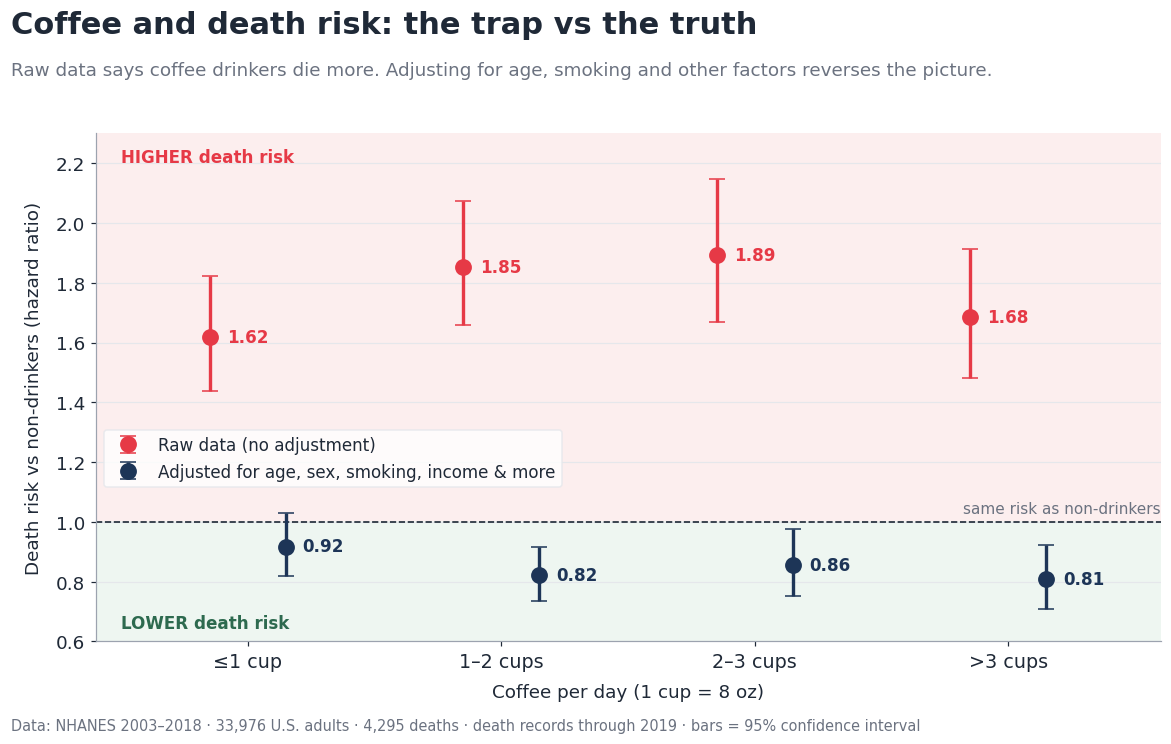

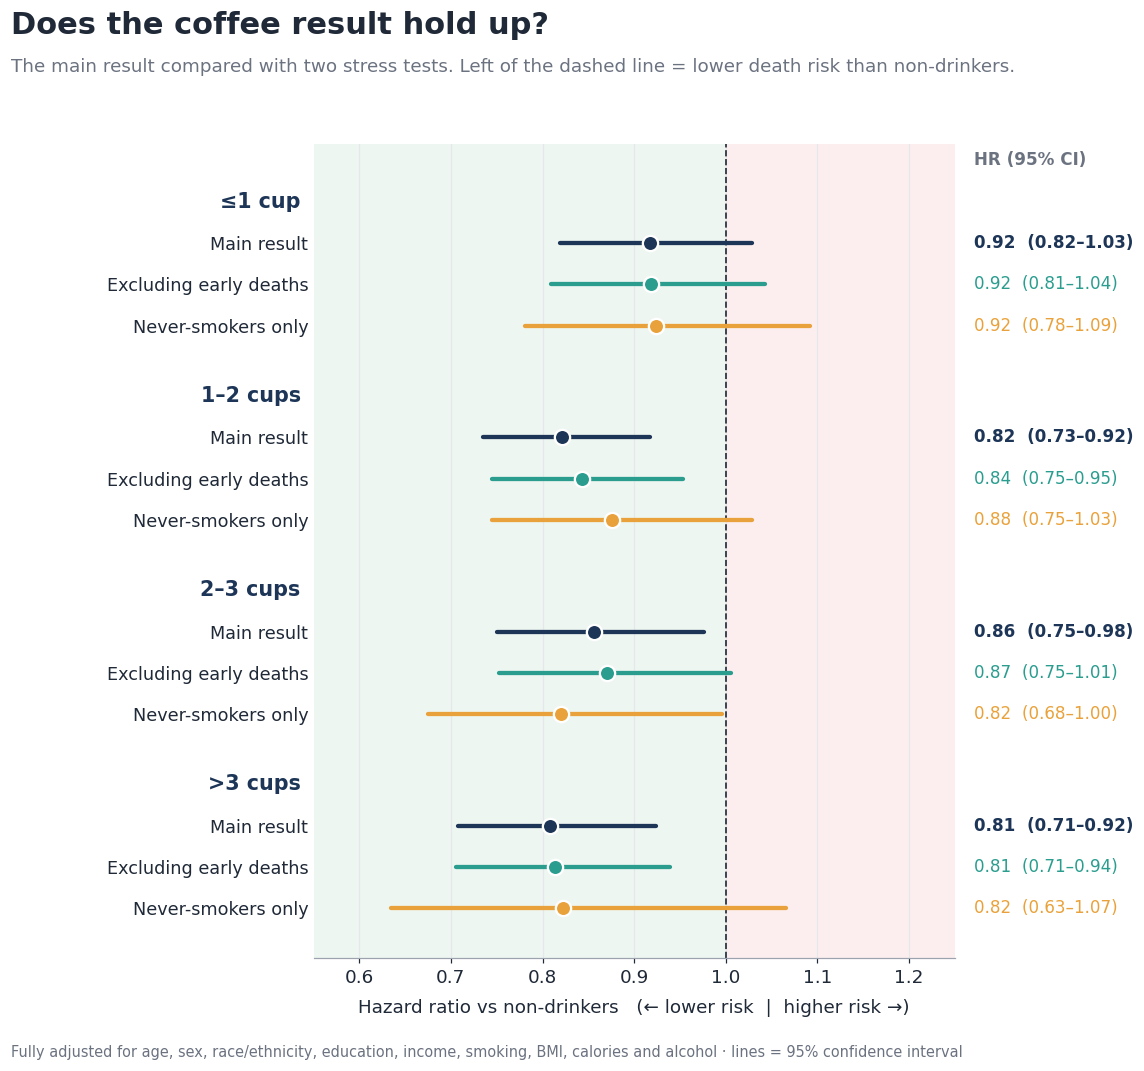

Saved: fig1_trap_vs_truth.png (307 KB)
Saved: fig2_forest_plot.png (458 KB)

✅ ALL GATES PASSED — figures saved.


In [9]:
# Step 4 begins. Now I turn the results into clean, professional graphs.
import matplotlib.pyplot as plt

# First, I set a professional publication-style palette.
BG, TEXT, MUTED, GRID = '#FFFFFF', '#1F2937', '#6B7280', '#E5E7EB'
NAVY, RED, TEAL, AMBER = '#1D3557', '#E63946', '#2A9D8F', '#E9A23B'
GOOD_TINT, BAD_TINT = '#EEF6F1', '#FCEEEE'
SENS_COL = {'Main (all adults)': NAVY, 'A. Excluding early deaths': TEAL, 'B. Never-smokers only': AMBER}

plt.rcParams.update({
    'font.size': 12, 'font.family': 'DejaVu Sans',
    'figure.facecolor': BG, 'axes.facecolor': BG, 'savefig.facecolor': BG,
    'text.color': TEXT, 'axes.labelcolor': TEXT, 'xtick.color': TEXT, 'ytick.color': TEXT,
    'axes.edgecolor': '#9CA3AF', 'axes.spines.top': False, 'axes.spines.right': False,
    'figure.dpi': 110, 'savefig.dpi': 300})
groups = labels[1:]

# I reload the results from the saved files, so the charts use exactly what was saved.
cox  = pd.read_csv(os.path.join(PROC, 'cox_results.csv'))
sens = pd.read_csv(os.path.join(PROC, 'sensitivity_results.csv'))

# ---------------- Figure 1: the trap vs the truth ----------------
# Now I pull the crude and fully adjusted results.
crude = cox[cox['Model'] == '1. Crude'].set_index('Coffee').loc[groups]
adj   = cox[cox['Model'] == '3. Fully adjusted'].set_index('Coffee').loc[groups]

# GATE 1: plotted values must match the in-memory results exactly.
for model_name, tbl in [('1. Crude', crude), ('3. Fully adjusted', adj)]:
    mem = res[res['Model'] == model_name].set_index('Coffee').loc[groups, 'HR']
    assert np.allclose(tbl['HR'].values, mem.values), f'GATE FAIL: {model_name} values differ from results'

# I reserve fixed space for the title, subtitle and chart, so nothing can overlap.
fig = plt.figure(figsize=(11, 7))
ax = fig.add_axes([0.09, 0.14, 0.88, 0.66])
fig.text(0.02, 0.93, 'Coffee and death risk: the trap vs the truth', fontsize=20, fontweight='bold')
fig.text(0.02, 0.875, 'Raw data says coffee drinkers die more. Adjusting for age, smoking and other '
         'factors reverses the picture.', fontsize=12, color=MUTED)

# Now I add soft zone tints, gridlines and the "no difference" line.
ax.axhspan(1, 2.3, color=BAD_TINT, zorder=0)
ax.axhspan(0.6, 1, color=GOOD_TINT, zorder=0)
ax.yaxis.grid(True, color=GRID, lw=0.8, zorder=1)
ax.set_axisbelow(True)
ax.axhline(1, color=TEXT, ls='--', lw=1.1, zorder=2)
ax.text(3.6, 1.02, 'same risk as non-drinkers', fontsize=10, ha='right', va='bottom', color=MUTED)
ax.text(-0.5, 2.22, 'HIGHER death risk', color=RED, fontsize=11, fontweight='bold', va='center')
ax.text(-0.5, 0.66, 'LOWER death risk', color='#2D6A4F', fontsize=11, fontweight='bold', va='center')

# Next, I draw both series with 95% confidence intervals and value labels.
x = np.arange(len(groups))
for tbl, offset, colour, name in [(crude, -0.15, RED,  'Raw data (no adjustment)'),
                                  (adj,    0.15, NAVY, 'Adjusted for age, sex, smoking, income & more')]:
    ax.errorbar(x + offset, tbl['HR'],
                yerr=[tbl['HR'] - tbl['CI_low'], tbl['CI_high'] - tbl['HR']],
                fmt='o', ms=10, capsize=5, lw=2.2, color=colour, label=name, zorder=3)
    for xi, hr in zip(x + offset, tbl['HR']):
        ax.annotate(f'{hr:.2f}', (xi, hr), xytext=(11, 0), textcoords='offset points',
                    va='center', fontsize=11, color=colour, fontweight='bold')

# I place the legend inside the empty band between 1.05 and 1.4, where no data falls.
ax.legend(loc='center left', bbox_to_anchor=(0.0, 0.36), frameon=True, facecolor=BG,
          edgecolor=GRID, fontsize=11)

ax.set_xticks(x, groups, fontsize=12.5)
ax.set_xlim(-0.6, len(groups) - 0.4)
ax.set_ylim(0.6, 2.3)
ax.set_xlabel('Coffee per day (1 cup = 8 oz)', labelpad=8)
ax.set_ylabel('Death risk vs non-drinkers (hazard ratio)', labelpad=8)
fig.text(0.02, 0.025, 'Data: NHANES 2003–2018 · 33,976 U.S. adults · 4,295 deaths · '
         'death records through 2019 · bars = 95% confidence interval', fontsize=9.5, color=MUTED)

f1 = os.path.join(FIGS, 'fig1_trap_vs_truth.png')
fig.savefig(f1)
plt.show()

# ---------------- Figure 2: forest plot ----------------
order = ['Main (all adults)', 'A. Excluding early deaths', 'B. Never-smokers only']
nice  = {'Main (all adults)': 'Main result',
         'A. Excluding early deaths': 'Excluding early deaths',
         'B. Never-smokers only': 'Never-smokers only'}

# GATE 1 (again): the main result must equal the Cox results, and all values must be finite.
main_file = sens[sens['Analysis'] == order[0]].set_index('Coffee').loc[groups, 'HR'].values
assert np.allclose(main_file, adj['HR'].values), 'GATE FAIL: forest plot main result differs from Cox results'
assert np.isfinite(sens[['HR', 'CI_low', 'CI_high']].values).all(), 'GATE FAIL: non-finite values'

# I reserve fixed space again: title on top, labels on the left, values on the right.
fig = plt.figure(figsize=(11, 10))
ax = fig.add_axes([0.27, 0.11, 0.53, 0.74])
fig.text(0.02, 0.95, 'Does the coffee result hold up?', fontsize=20, fontweight='bold')
fig.text(0.02, 0.915, 'The main result compared with two stress tests. Left of the dashed line = '
         'lower death risk than non-drinkers.', fontsize=12, color=MUTED)

ax.axvspan(0.55, 1, color=GOOD_TINT, zorder=0)
ax.axvspan(1, 1.25, color=BAD_TINT, zorder=0)
ax.xaxis.grid(True, color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.axvline(1, color=TEXT, ls='--', lw=1.1)

# Now I draw a header for each coffee level, then one row per analysis underneath it.
y, yticks, ylabels = 0, [], []
for g in groups:
    ax.text(-0.02, y, g, fontsize=13.5, fontweight='bold', color=NAVY, ha='right', va='center',
            transform=ax.get_yaxis_transform())
    y -= 1
    for a in order:
        r = sens[(sens['Analysis'] == a) & (sens['Coffee'] == g)].iloc[0]
        ax.plot([r.CI_low, r.CI_high], [y, y], color=SENS_COL[a], lw=2.8, solid_capstyle='round', zorder=3)
        ax.plot(r.HR, y, 'o', ms=10, color=SENS_COL[a], markeredgecolor=BG, markeredgewidth=1.5, zorder=4)
        ax.text(1.03, y, f'{r.HR:.2f}  ({r.CI_low:.2f}–{r.CI_high:.2f})', va='center',
                fontsize=11, color=SENS_COL[a], fontweight='bold' if a == order[0] else 'normal',
                transform=ax.get_yaxis_transform())
        yticks.append(y); ylabels.append(nice[a])
        y -= 1
    y -= 0.7

ax.text(1.03, 0.9, 'HR (95% CI)', fontsize=11, fontweight='bold', color=MUTED,
        transform=ax.get_yaxis_transform())
ax.set_yticks(yticks, ylabels, fontsize=11.5)
ax.set_xlim(0.55, 1.25)
ax.set_ylim(y + 0.5, 1.4)
ax.set_xlabel('Hazard ratio vs non-drinkers   (← lower risk  |  higher risk →)', labelpad=8)
ax.spines['left'].set_visible(False)
ax.tick_params(axis='y', length=0)
fig.text(0.02, 0.02, 'Fully adjusted for age, sex, race/ethnicity, education, income, smoking, BMI, '
         'calories and alcohol · lines = 95% confidence interval', fontsize=9.5, color=MUTED)

f2 = os.path.join(FIGS, 'fig2_forest_plot.png')
fig.savefig(f2)
plt.show()

# GATE 2: both figure files must exist and not be empty.
for f in [f1, f2]:
    assert os.path.exists(f) and os.path.getsize(f) > 10_000, f'GATE FAIL: {f} missing or empty'
    print(f'Saved: {os.path.basename(f)} ({os.path.getsize(f)/1024:.0f} KB)')
print('\n✅ ALL GATES PASSED — figures saved.')